In [6]:
# Install kaggle API
!pip install kaggle

# Upload your Kaggle API key to use the Kaggle dataset
from google.colab import files
files.upload()

# Set Kaggle API key location
import os
os.environ['KAGGLE_CONFIG_DIR'] = "/root/.kaggle"

# Download dataset from Kaggle
!kaggle datasets download -d andrewmvd/lung-and-colon-cancer-histopathological-images

# Unzip the downloaded dataset
!unzip lung-and-colon-cancer-histopathological-images.zip


Streaming output truncated to the last 5000 lines.
  inflating: lung_colon_image_set/lung_image_sets/lung_scc/lungscc1.jpeg  
  inflating: lung_colon_image_set/lung_image_sets/lung_scc/lungscc10.jpeg  
  inflating: lung_colon_image_set/lung_image_sets/lung_scc/lungscc100.jpeg  
  inflating: lung_colon_image_set/lung_image_sets/lung_scc/lungscc1000.jpeg  
  inflating: lung_colon_image_set/lung_image_sets/lung_scc/lungscc1001.jpeg  
  inflating: lung_colon_image_set/lung_image_sets/lung_scc/lungscc1002.jpeg  
  inflating: lung_colon_image_set/lung_image_sets/lung_scc/lungscc1003.jpeg  
  inflating: lung_colon_image_set/lung_image_sets/lung_scc/lungscc1004.jpeg  
  inflating: lung_colon_image_set/lung_image_sets/lung_scc/lungscc1005.jpeg  
  inflating: lung_colon_image_set/lung_image_sets/lung_scc/lungscc1006.jpeg  
  inflating: lung_colon_image_set/lung_image_sets/lung_scc/lungscc1007.jpeg  
  inflating: lung_colon_image_set/lung_image_sets/lung_scc/lungscc1008.jpeg  
  inflating: lung_c

In [5]:
import os
import re
import requests
from PIL import Image
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers
from tensorflow.keras.preprocessing import image
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from tensorflow.keras.optimizers import Nadam
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

In [7]:
# Set data directory path
data_dir = '/content/lung_colon_image_set/colon_image_sets'

# Initialize empty lists to store file paths and labels
filepaths = []
labels = []

# Filter for colon cancer images only (Colon Adenocarcinoma and Colon Benign Tissue)
colon_classes = ['colon_aca', 'colon_n']

# Iterate through the data directory to gather relevant image paths and labels
for fold in os.listdir(data_dir):
    if fold in colon_classes:
        foldpath = os.path.join(data_dir, fold)
        for f in os.listdir(foldpath):
            fpath = os.path.join(foldpath, f)
            filepaths.append(fpath)
            if fold == 'colon_aca':
                labels.append('Colon Adenocarcinoma')
            elif fold == 'colon_n':
                labels.append('Colon Benign Tissue')

# Create a DataFrame with image paths and labels
df = pd.DataFrame({
    'filepaths': filepaths,
    'labels': labels
})

# Display the first few rows of the DataFrame
df.head()


,filepaths,labels
0,/content/lung_colon_image_set/colon_image_sets...,Colon Adenocarcinoma
1,/content/lung_colon_image_set/colon_image_sets...,Colon Adenocarcinoma
2,/content/lung_colon_image_set/colon_image_sets...,Colon Adenocarcinoma
3,/content/lung_colon_image_set/colon_image_sets...,Colon Adenocarcinoma
4,/content/lung_colon_image_set/colon_image_sets...,Colon Adenocarcinoma


In [8]:
# Split the data into training, validation, and test sets
train_df, temp_df = train_test_split(df, train_size=0.8, stratify=df['labels'], random_state=42)
valid_df, test_df = train_test_split(temp_df, train_size=0.5, stratify=temp_df['labels'], random_state=42)

# Show the sizes of the splits
print(f"Training set size: {len(train_df)}")
print(f"Validation set size: {len(valid_df)}")
print(f"Test set size: {len(test_df)}")


Training set size: 8000
Validation set size: 1000
Test set size: 1000


In [9]:
# Image size and batch size
img_size = (224, 224)
batch_size = 64

# Image data generators for training, validation, and testing
train_gen = ImageDataGenerator(rescale=1./255, horizontal_flip=True, rotation_range=30, zoom_range=0.2)
valid_gen = ImageDataGenerator(rescale=1./255)
test_gen = ImageDataGenerator(rescale=1./255)

# Create data generators using the dataframe
train_flow = train_gen.flow_from_dataframe(train_df, x_col='filepaths', y_col='labels', target_size=img_size,
                                           class_mode='categorical', batch_size=batch_size, shuffle=True)
valid_flow = valid_gen.flow_from_dataframe(valid_df, x_col='filepaths', y_col='labels', target_size=img_size,
                                           class_mode='categorical', batch_size=batch_size, shuffle=False)
test_flow = test_gen.flow_from_dataframe(test_df, x_col='filepaths', y_col='labels', target_size=img_size,
                                         class_mode='categorical', batch_size=batch_size, shuffle=False)


Found 8000 validated image filenames belonging to 2 classes.
Found 1000 validated image filenames belonging to 2 classes.
Found 1000 validated image filenames belonging to 2 classes.


In [10]:
# Build a CNN model for classification
model = Sequential([
    Conv2D(64, (3, 3), activation='relu', input_shape=(224, 224, 3), padding='same'),
    MaxPooling2D((2, 2)),

    Conv2D(128, (3, 3), activation='relu', padding='same'),
    MaxPooling2D((2, 2)),

    Conv2D(256, (3, 3), activation='relu', padding='same'),
    MaxPooling2D((2, 2)),

    Flatten(),
    Dense(512, activation='relu'),
    Dropout(0.5),
    Dense(2, activation='softmax')  # 2 output classes: Colon Adenocarcinoma and Colon Benign Tissue
])

# Compile the model
model.compile(optimizer=Nadam(learning_rate=0.0001), loss='categorical_crossentropy', metrics=['accuracy'])

# Print the model summary
model.summary()


/usr/local/lib/python3.10/dist-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 224, 224, 64)        │           1,792 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 112, 112, 64)        │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 112, 112, 128)       │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 56, 56, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 56, 56, 256)         │         295,168 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 28, 28, 256)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 200704)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 512)                 │     102,760,960 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 512)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 2)                   │           1,026 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 103,132,802 (393.42 MB)

 Trainable params: 103,132,802 (393.42 MB)

 Non-trainable params: 0 (0.00 B)

In [11]:
# Set early stopping and model checkpoint
early_stopping = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
model_checkpoint = ModelCheckpoint('colon_cancer_model.keras', monitor='val_loss', save_best_only=True)

# Train the model
history = model.fit(train_flow, epochs=20, validation_data=valid_flow,
                    callbacks=[early_stopping, model_checkpoint], verbose=1)


Epoch 1/20


/usr/local/lib/python3.10/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:122: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


125/125 ━━━━━━━━━━━━━━━━━━━━ 174s 1s/step - accuracy: 0.6261 - loss: 0.7017 - val_accuracy: 0.7510 - val_loss: 0.5068
Epoch 2/20
125/125 ━━━━━━━━━━━━━━━━━━━━ 177s 1s/step - accuracy: 0.8374 - loss: 0.3645 - val_accuracy: 0.9210 - val_loss: 0.2159
Epoch 3/20
125/125 ━━━━━━━━━━━━━━━━━━━━ 128s 969ms/step - accuracy: 0.8881 - loss: 0.2608 - val_accuracy: 0.8980 - val_loss: 0.2364
Epoch 4/20
125/125 ━━━━━━━━━━━━━━━━━━━━ 129s 972ms/step - accuracy: 0.9204 - loss: 0.2029 - val_accuracy: 0.8750 - val_loss: 0.3019
Epoch 5/20
125/125 ━━━━━━━━━━━━━━━━━━━━ 148s 1s/step - accuracy: 0.9464 - loss: 0.1485 - val_accuracy: 0.9640 - val_loss: 0.0888
Epoch 6/20
125/125 ━━━━━━━━━━━━━━━━━━━━ 182s 984ms/step - accuracy: 0.9587 - loss: 0.1147 - val_accuracy: 0.9190 - val_loss: 0.1737
Epoch 7/20
125/125 ━━━━━━━━━━━━━━━━━━━━ 127s 969ms/step - accuracy: 0.9690 - loss: 0.0903 - val_accuracy: 0.9490 - val_loss: 0.1228
Epoch 8/20
125/125 ━━━━━━━━━━━━━━━━━━━━ 127s 965ms/step - accuracy: 0.9799 - loss: 0.0668 - val_

In [12]:
# Evaluate the model on the test data
test_loss, test_accuracy = model.evaluate(test_flow, verbose=1)
print(f"Test Loss: {test_loss}")
print(f"Test Accuracy: {test_accuracy}")


16/16 ━━━━━━━━━━━━━━━━━━━━ 7s 408ms/step - accuracy: 0.9954 - loss: 0.0217
Test Loss: 0.022838206961750984
Test Accuracy: 0.9919999837875366


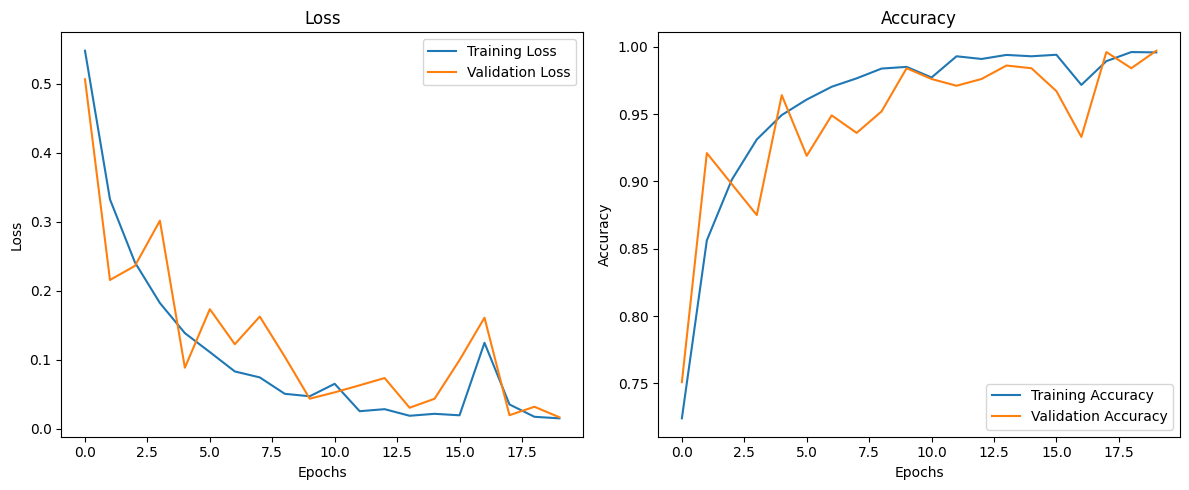

In [13]:
# Plot training and validation loss and accuracy
plt.figure(figsize=(12, 5))

# Plot loss
plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

# Plot accuracy
plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

plt.tight_layout()
plt.show()


16/16 ━━━━━━━━━━━━━━━━━━━━ 8s 344ms/step


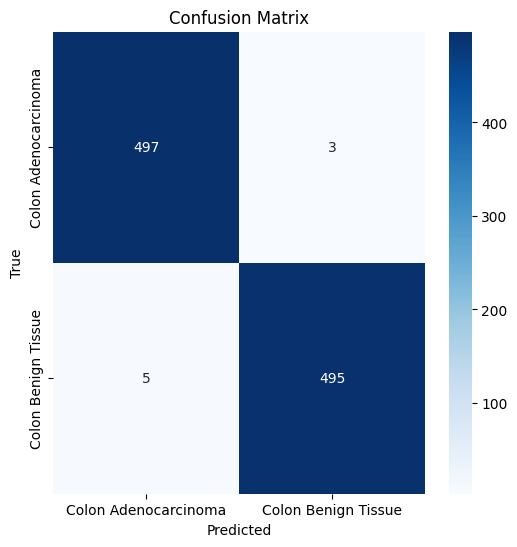

In [14]:
# Make predictions on the test set
predictions = model.predict(test_flow, verbose=1)
y_pred = np.argmax(predictions, axis=1)
y_true = test_flow.classes

# Generate confusion matrix
conf_matrix = confusion_matrix(y_true, y_pred)

# Plot confusion matrix
plt.figure(figsize=(6, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=test_flow.class_indices.keys(),
            yticklabels=test_flow.class_indices.keys())
plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.show()
